# Data analysis

Dataset overview for TAPP inguinal hernia repair: videos, frames, phase annotations and phase groups.

## Setup

Imports, paths and config.

In [14]:
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

from surgphase.config import (
    ANNOTATIONS_DIR,
    FPS,
    FRAMES_DIR,
    PATIENTS,
    PHASE_GROUP_FILE,
    ROOT_DIR,
    UNLABELLED,
    VIDEOS_DIR,
)
from surgphase.data import (
    PhaseMapper,
    load_phase_group,
    load_surgeries,
    merge_phases,
    parse_merge,
)
from surgphase.eval.metrics import segments
from surgphase.eval.splits import leave_one_surgery_out
from surgphase.viz import SEQUENTIAL, phase_colors, plot_timeline, style_axes
from surgphase.viz.style import GRIDLINE, INK, MUTED_INK, SECONDARY_INK, SURFACE

ANNOTATION_ID = "default"
ANNOTATIONS_FILE = ANNOTATIONS_DIR / ANNOTATION_ID / "annotated_frames.csv"
ANALYSIS_FPS = 1.0
NEUTRAL_PHASE = "P0"
MERGES = [parse_merge("P5+P6")]
DIVERGING = LinearSegmentedColormap.from_list("surgphase_diverging", ["#256abf", "#f0efec", "#e34948"])

## Load data

Annotation segments per surgery, annotated-frame CSVs and phase group definitions.

In [15]:
phase_group = load_phase_group(PHASE_GROUP_FILE)
mapper = PhaseMapper(phase_group)
phase_ids = mapper.get_all_phase_ids()
phase_names = [f"{phase.id} {phase.name}" for phase in mapper.phases]
colors = phase_colors(len(phase_ids), neutral_phase=mapper.map_to_index(NEUTRAL_PHASE))

frames = pd.read_csv(ANNOTATIONS_FILE, dtype={"phase_id": "string"})
surgeries = load_surgeries(ANNOTATIONS_FILE, phase_group, ROOT_DIR, ANALYSIS_FPS)
labels = {surgery_id: surgery.labels for surgery_id, surgery in surgeries.items()}

segment_rows = []
for surgery_id, sequence in labels.items():
    runs = segments(sequence)
    for label, start, end in zip(runs.labels, runs.starts, runs.ends, strict=True):
        if label == UNLABELLED:
            continue
        segment_rows.append(
            {
                "surgery": surgery_id,
                "phase": phase_ids[label],
                "start": int(start),
                "end": int(end),
                "start_min": start / ANALYSIS_FPS / 60,
                "duration_min": (end - start) / ANALYSIS_FPS / 60,
            }
        )
segment_table = pd.DataFrame(segment_rows).sort_values(["surgery", "start"], ignore_index=True)

print(
    f"{len(frames):,} annotated frame rows, {len(surgeries)} surgeries at {ANALYSIS_FPS:g} fps, "
    f"{len(segment_table)} phase segments"
)

694,962 annotated frame rows, 7 surgeries at 1 fps, 43 phase segments


## Dataset summary

Surgeries, durations, frame counts per FPS and unlabelled frames.

In [27]:
def count_frames(directory):
    return sum(1 for _ in directory.glob("frame_*.png")) if directory.is_dir() else 0


on_disk = pd.DataFrame(
    {f"frames fps{fps:g}": {s: count_frames(FRAMES_DIR / s / f"fps{fps:g}") for s in PATIENTS} for fps in FPS}
)
on_disk = on_disk.loc[:, on_disk.sum() > 0]

annotated = (
    frames.groupby(["surgery_id", "sample_rate"]).size().unstack(fill_value=0)
    .rename(columns=lambda fps: f"annotated fps{fps:g}")
)
unlabelled = (
    frames[frames["phase_id"].isna()].groupby(["surgery_id", "sample_rate"]).size().unstack(fill_value=0)
    .rename(columns=lambda fps: f"unlabelled fps{fps:g}")
)

summary = pd.DataFrame(
    {
        "video": {s: (VIDEOS_DIR / f"{s}.mp4").is_file() for s in PATIENTS},
        "annotation json": {s: (ANNOTATIONS_DIR / ANNOTATION_ID / f"{s}.json").is_file() for s in PATIENTS},
        "labelled min": {
            s: (labels[s] != UNLABELLED).sum() / ANALYSIS_FPS / 60 if s in labels else 0.0 for s in PATIENTS
        },
    }
)
summary = (
    summary.join(on_disk).join(annotated).join(unlabelled)
    .fillna(0)
    .astype({column: int for column in [*on_disk, *annotated, *unlabelled]})
    .round({"labelled min": 1})
)

not_annotated = [s for s in PATIENTS if s not in labels]
if not_annotated:
    print(f"not in {ANNOTATIONS_FILE.name} at {ANALYSIS_FPS:g} fps: {not_annotated}")
summary

,video,annotation json,labelled min,frames fps1,frames fps15,frames fps30,annotated fps1,annotated fps15,annotated fps30
pat01,True,True,16.0,962,14434,28868,962,14434,28868
pat02,True,True,13.0,781,11718,23436,781,11718,23436
pat03,True,True,30.6,1839,27587,55173,1839,27587,55173
pat04,True,True,28.0,1681,25218,50436,1681,25218,50436
pat05,True,True,58.4,3502,52534,105067,3502,52534,105067
pat06,True,True,68.0,4080,61198,122396,4080,61198,122396
pat07,True,True,37.7,2262,33930,67860,2262,33930,67860


## Surgery length differences

How much the video length varies between surgeries: each surgery against the median and the shortest one.

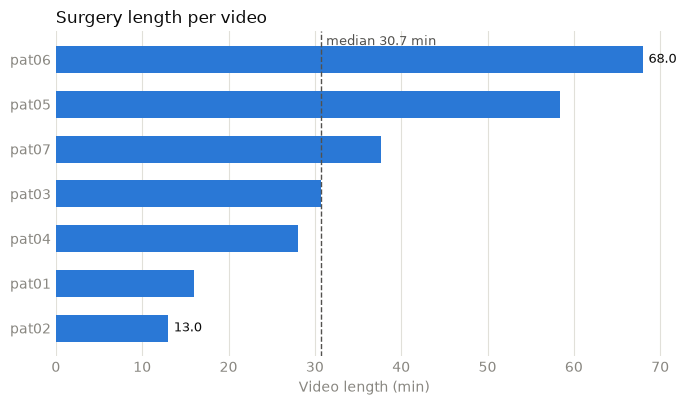

range 13.0-68.0 min, longest is 5.2x the shortest, coefficient of variation 57%


,minutes,vs median (min),vs median (%),x shortest
pat02,13.0,-17.6,-57.5,1.0
pat01,16.0,-14.6,-47.7,1.2
pat04,28.0,-2.6,-8.6,2.2
pat03,30.7,0.0,0.0,2.4
pat07,37.7,7.0,23.0,2.9
pat05,58.4,27.7,90.4,4.5
pat06,68.0,37.3,121.8,5.2


In [17]:
import subprocess

import matplotlib.pyplot as plt
import pandas as pd

from surgphase.config import PATIENTS, VIDEOS_DIR


def video_minutes(path):
    command = [
        "ffprobe", "-v", "error",
        "-show_entries", "format=duration",
        "-of", "default=noprint_wrappers=1:nokey=1",
        str(path),
    ]
    output = subprocess.run(command, capture_output=True, text=True, check=True).stdout
    return float(output) / 60


lengths = pd.Series(
    {
        surgery: video_minutes(VIDEOS_DIR / f"{surgery}.mp4")
        for surgery in PATIENTS
        if (VIDEOS_DIR / f"{surgery}.mp4").is_file()
    },
    name="minutes",
).sort_values()
missing = sorted(set(PATIENTS) - set(lengths.index))

median = lengths.median()
length_table = pd.DataFrame(
    {
        "minutes": lengths,
        "vs median (min)": lengths - median,
        "vs median (%)": (lengths / median - 1) * 100,
        "x shortest": lengths / lengths.min(),
    }
).round(1)

fig, ax = plt.subplots(figsize=(7, 0.45 * len(lengths) + 1))
ax.barh(lengths.index, lengths, height=0.6, color="#2a78d6")
ax.axvline(median, color="#52514e", linewidth=1, linestyle="--")
ax.annotate(
    f"median {median:.1f} min",
    (median, 1),
    xycoords=("data", "axes fraction"),
    xytext=(4, -2),
    textcoords="offset points",
    va="top",
    fontsize=9,
    color="#52514e",
)
for surgery in (lengths.index[0], lengths.index[-1]):
    ax.annotate(
        f"{lengths[surgery]:.1f}",
        (lengths[surgery], surgery),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        color="#0b0b0b",
    )
ax.set_xlabel("Video length (min)", color="#898781")
ax.set_title("Surgery length per video", loc="left", color="#0b0b0b")
ax.tick_params(colors="#898781", length=0)
ax.grid(axis="x", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_visible(False)
plt.tight_layout()
plt.show()

print(
    f"range {lengths.min():.1f}-{lengths.max():.1f} min, "
    f"longest is {lengths.max() / lengths.min():.1f}x the shortest, "
    f"coefficient of variation {lengths.std() / lengths.mean():.0%}"
)
if missing:
    print(f"no video for {missing}")
length_table

## Phase taxonomy

Phases of the `default` group and how the `P5+P6` merge maps onto them.

In [18]:
merged_group = merge_phases(phase_group, MERGES)
merged_into = {member: phase.id for phase in merged_group.phases.values() for member in phase.members}

taxonomy = pd.DataFrame(
    [
        {"id": phase.id, "order": phase.order, "name": phase.name, merged_group.name: merged_into[phase.id]}
        for phase in mapper.phases
    ]
).set_index("id")

print(phase_group.surgery_name)
print(textwrap.fill(phase_group.description, 100))
taxonomy

Transabdominal preperitoneal (TAPP) laparoscopic inguinal hernia repair.
The surgeon inspects the inguinal region, incises the peritoneum, develops the preperitoneal space,
dissects and reduces the hernia sac, introduces and positions a prosthetic mesh, secures the mesh
using a tacking device, and closes the peritoneal flap. Additional suturing may be performed to
complete closure.


,order,name,default_P5+P6
id,,,
P0,0,No surgical activity,P0
P1,1,Preparation,P1
P2,2,Peritoneal flap incision,P2
P3,3,Peritoneal flap dissection,P3
P4,4,Hernia dissection,P4
P5,5,Mesh deployment,P5
P6,6,Peritoneal flap closure,P5


## Ground-truth timelines

Phase sequence per surgery over time.

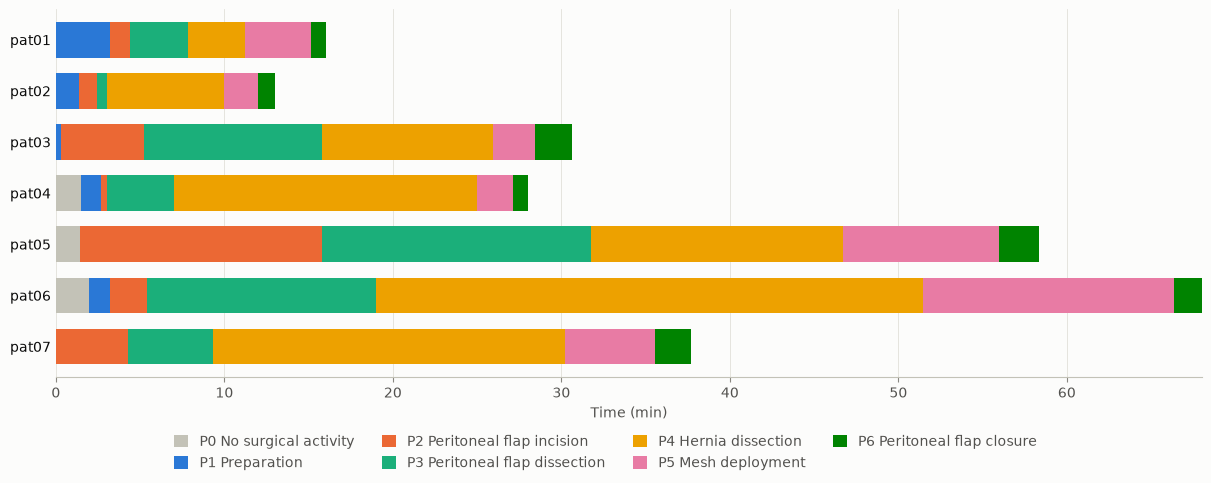

In [19]:
plot_timeline(labels, phase_names, colors, ANALYSIS_FPS)
plt.show()

## Phase distribution

Frame share per phase, overall and per surgery. Shows class imbalance.

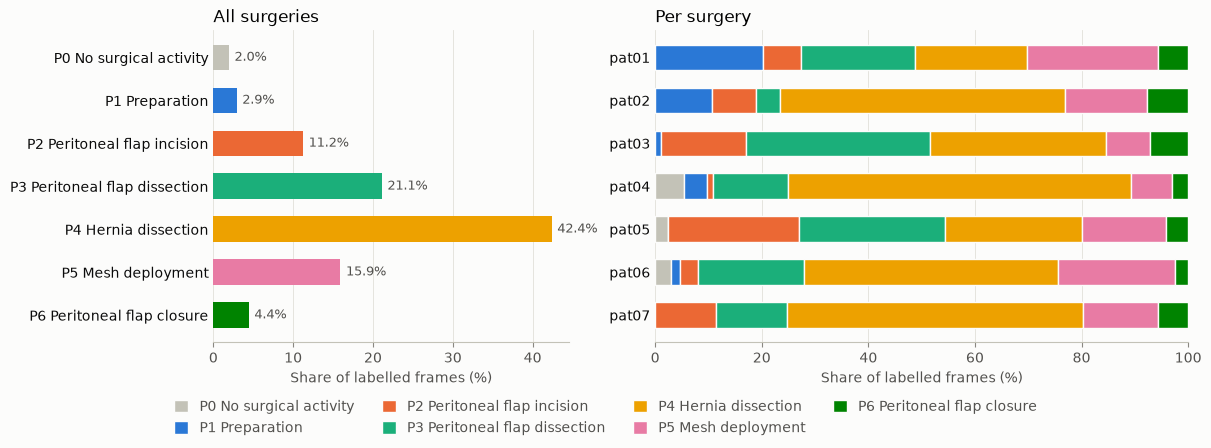

imbalance: largest phase P4 is 21.7x the smallest P0


,P0,P1,P2,P3,P4,P5,P6
pat01,0.0,20.2,7.2,21.4,21.1,24.5,5.6
pat02,0.0,10.6,8.3,4.5,53.4,15.4,7.8
pat03,0.0,1.1,15.9,34.5,33.1,8.2,7.2
pat04,5.4,4.2,1.2,14.1,64.2,7.7,3.1
pat05,2.5,0.0,24.6,27.4,25.6,15.8,4.1
pat06,2.9,1.8,3.3,20.0,47.7,22.0,2.4
pat07,0.0,0.0,11.4,13.4,55.4,14.1,5.7
all,2.0,2.9,11.2,21.1,42.4,15.9,4.4


In [20]:
counts = pd.DataFrame(
    {s: np.bincount(y[y != UNLABELLED], minlength=len(phase_ids)) for s, y in labels.items()},
    index=phase_ids,
).T
share = counts.div(counts.sum(axis=1), axis=0) * 100
overall = counts.sum() / counts.to_numpy().sum() * 100

fig, (left, right) = plt.subplots(
    1, 2, figsize=(12, 0.4 * max(len(phase_ids), len(share)) + 1.6),
    layout="constrained", gridspec_kw={"width_ratios": [1, 1.5]},
)
for ax in (left, right):
    style_axes(ax)
    ax.grid(axis="x", color=GRIDLINE, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0, labelcolor=INK)

positions = np.arange(len(phase_ids))
left.barh(positions, overall.to_numpy(), height=0.6, color=colors)
for position, value in zip(positions, overall, strict=True):
    left.annotate(f"{value:.1f}%", (value, position), xytext=(4, 0), textcoords="offset points",
                  va="center", fontsize=9, color=SECONDARY_INK)
left.set_yticks(positions, labels=phase_names)
left.invert_yaxis()
left.set_xlabel("Share of labelled frames (%)")
left.set_title("All surgeries", loc="left")

rows = np.arange(len(share))
offset = np.zeros(len(share))
for index, phase in enumerate(phase_ids):
    right.barh(rows, share[phase], left=offset, height=0.6, color=colors[index],
               edgecolor=SURFACE, linewidth=1, label=phase_names[index])
    offset += share[phase].to_numpy()
right.set_yticks(rows, labels=share.index)
right.invert_yaxis()
right.set_xlim(0, 100)
right.set_xlabel("Share of labelled frames (%)")
right.set_title("Per surgery", loc="left")
fig.legend(*right.get_legend_handles_labels(), loc="outside lower center", ncol=4,
           frameon=False, handlelength=1.0, handleheight=1.0, labelcolor=SECONDARY_INK)
plt.show()

present = overall[overall > 0]
print(f"imbalance: largest phase {present.idxmax()} is {present.max() / present.min():.1f}x the smallest {present.idxmin()}")
pd.concat([share, overall.rename("all").to_frame().T]).round(1)

## Phase durations

Duration of each phase across surgeries, absolute and normalised by surgery length.

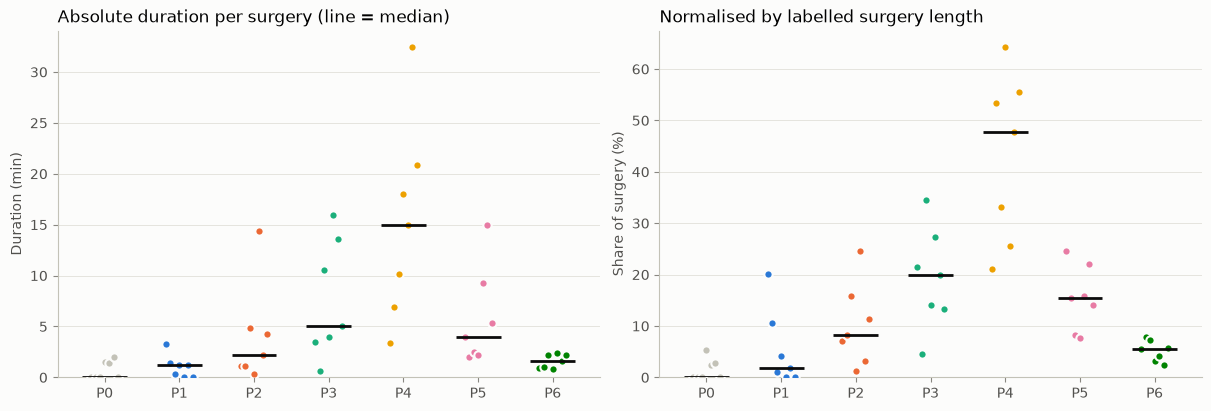

,median min,min min,max min,median %,cv
phase,,,,,
P0,0.00,0.00,1.97,0.00,1.27
P1,1.18,0.00,3.23,1.81,1.07
P2,2.22,0.35,14.35,8.32,1.20
P3,5.05,0.58,15.97,19.98,0.76
P4,14.95,3.38,32.43,47.70,0.64
P5,3.93,2.00,14.95,15.36,0.84
P6,1.62,0.87,2.42,5.61,0.42


In [21]:
phase_minutes = (
    segment_table.pivot_table(index="surgery", columns="phase", values="duration_min", aggfunc="sum", fill_value=0)
    .reindex(index=list(labels), columns=phase_ids, fill_value=0)
)
phase_percent = phase_minutes.div(phase_minutes.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
spread = np.linspace(-0.18, 0.18, len(phase_minutes))
for ax, table, ylabel in ((axes[0], phase_minutes, "Duration (min)"), (axes[1], phase_percent, "Share of surgery (%)")):
    style_axes(ax)
    ax.grid(axis="y", color=GRIDLINE, linewidth=0.6)
    ax.set_axisbelow(True)
    for index, phase in enumerate(phase_ids):
        values = table[phase].to_numpy()
        ax.scatter(index + spread, values, s=36, color=colors[index], edgecolor=SURFACE, linewidth=1.5, zorder=3)
        ax.hlines(np.median(values), index - 0.3, index + 0.3, color=INK, linewidth=2, zorder=4)
    ax.set_xticks(range(len(phase_ids)), labels=phase_ids)
    ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)
axes[0].set_title("Absolute duration per surgery (line = median)", loc="left")
axes[1].set_title("Normalised by labelled surgery length", loc="left")
plt.show()

pd.DataFrame(
    {
        "median min": phase_minutes.median(),
        "min min": phase_minutes.min(),
        "max min": phase_minutes.max(),
        "median %": phase_percent.median(),
        "cv": phase_minutes.std() / phase_minutes.mean(),
    }
).round(2)

## Phase occurrence and order

Which phases appear in each surgery, how often they recur and whether the canonical order holds.

In [22]:
phase_order = {phase.id: phase.order for phase in mapper.phases}


def order_summary(group):
    sequence = [phase for phase in group.sort_values("start")["phase"] if phase != NEUTRAL_PHASE]
    collapsed = [phase for index, phase in enumerate(sequence) if index == 0 or phase != sequence[index - 1]]
    backward = sum(phase_order[b] < phase_order[a] for a, b in zip(collapsed, collapsed[1:]))
    skipped = [p for p in phase_ids if p != NEUTRAL_PHASE and p not in collapsed]
    return {
        "sequence": " → ".join(collapsed),
        "backward steps": backward,
        "missing": ", ".join(skipped),
        "canonical": backward == 0 and not skipped,
    }


occurrence = (
    segment_table.groupby(["surgery", "phase"]).size().unstack(fill_value=0)
    .reindex(index=list(labels), columns=phase_ids, fill_value=0)
)
order_table = pd.DataFrame({s: order_summary(g) for s, g in segment_table.groupby("surgery")}).T

print(f"segments per phase (0 = absent); order ignores {NEUTRAL_PHASE} and collapses repeats")
display(occurrence.style.background_gradient(cmap=SEQUENTIAL, vmin=0))
order_table

segments per phase (0 = absent); order ignores P0 and collapses repeats


phase,P0,P1,P2,P3,P4,P5,P6
surgery,,,,,,,
pat01,0,1,1,1,1,1,1
pat02,0,1,1,1,1,1,1
pat03,0,1,1,1,1,1,1
pat04,1,1,1,1,1,1,1
pat05,1,0,1,1,1,1,1
pat06,1,1,1,1,1,1,1
pat07,0,0,1,1,1,1,1


,sequence,backward steps,missing,canonical
pat01,P1 → P2 → P3 → P4 → P5 → P6,0,,True
pat02,P1 → P2 → P3 → P4 → P5 → P6,0,,True
pat03,P1 → P2 → P3 → P4 → P5 → P6,0,,True
pat04,P1 → P2 → P3 → P4 → P5 → P6,0,,True
pat05,P2 → P3 → P4 → P5 → P6,0,P1,False
pat06,P1 → P2 → P3 → P4 → P5 → P6,0,,True
pat07,P2 → P3 → P4 → P5 → P6,0,P1,False


## Phase transitions

Transition counts between phases. The empirical prior behind the HMM.

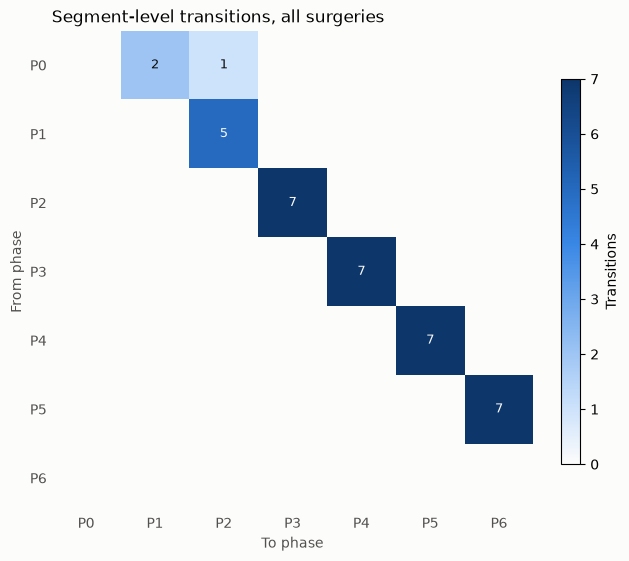

row-normalised transition probabilities (self-transitions excluded)


,P0,P1,P2,P3,P4,P5,P6
P0,0.0,0.67,0.33,0.0,0.0,0.0,0.0
P1,0.0,0.00,1.00,0.0,0.0,0.0,0.0
P2,0.0,0.00,0.00,1.0,0.0,0.0,0.0
P3,0.0,0.00,0.00,0.0,1.0,0.0,0.0
P4,0.0,0.00,0.00,0.0,0.0,1.0,0.0
P5,0.0,0.00,0.00,0.0,0.0,0.0,1.0
P6,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
transitions = pd.DataFrame(0, index=phase_ids, columns=phase_ids)
for _, group in segment_table.groupby("surgery"):
    sequence = group.sort_values("start")["phase"].tolist()
    for source, target in zip(sequence, sequence[1:]):
        if source != target:
            transitions.loc[source, target] += 1

fig, ax = plt.subplots(figsize=(6.5, 5.5), layout="constrained")
style_axes(ax)
image = ax.imshow(transitions.to_numpy(), cmap=SEQUENTIAL, vmin=0)
peak = max(transitions.to_numpy().max(), 1)
for row, source in enumerate(phase_ids):
    for column, target in enumerate(phase_ids):
        value = transitions.loc[source, target]
        if value:
            ax.text(column, row, value, ha="center", va="center", fontsize=9,
                    color=SURFACE if value > peak / 2 else INK)
ax.set_xticks(range(len(phase_ids)), labels=phase_ids)
ax.set_yticks(range(len(phase_ids)), labels=phase_ids)
ax.set_xlabel("To phase")
ax.set_ylabel("From phase")
ax.set_title("Segment-level transitions, all surgeries", loc="left")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)
fig.colorbar(image, ax=ax, shrink=0.8, label="Transitions")
plt.show()

print("row-normalised transition probabilities (self-transitions excluded)")
transitions.div(transitions.sum(axis=1).replace(0, np.nan), axis=0).round(2)

## Segment lengths

Distribution of contiguous segment lengths per phase. Informs smoothing windows.

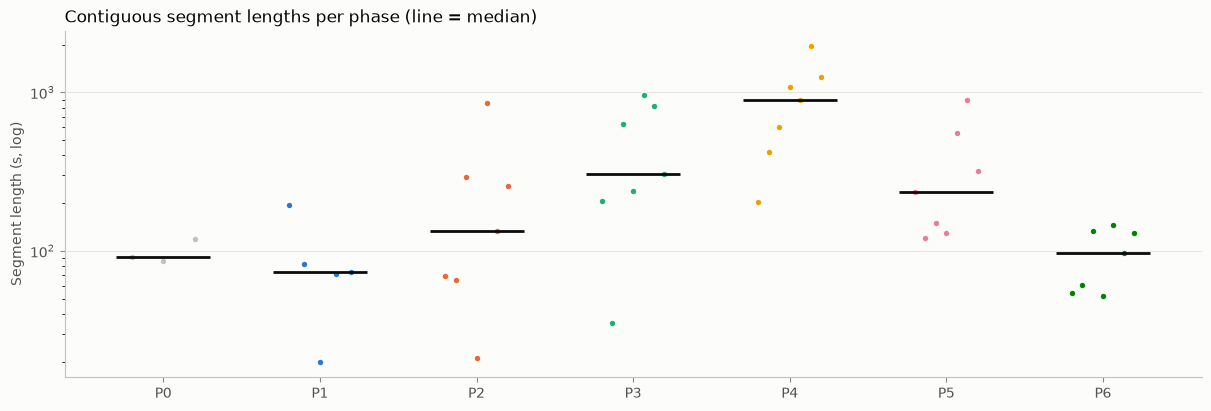

,count,mean,std,min,10%,50%,max
phase,,,,,,,
P0,3.0,98.3,17.2,86.0,87.0,91.0,118.0
P1,5.0,88.4,64.0,20.0,40.4,74.0,194.0
P2,7.0,242.7,291.0,21.0,47.4,133.0,861.0
P3,7.0,455.6,347.4,35.0,137.6,303.0,958.0
P4,7.0,915.0,585.2,203.0,331.4,897.0,1946.0
P5,7.0,343.7,287.7,120.0,125.4,236.0,897.0
P6,7.0,95.9,40.4,52.0,53.2,97.0,145.0


In [24]:
segment_seconds = segment_table.assign(seconds=segment_table["duration_min"] * 60)

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
style_axes(ax)
ax.grid(axis="y", color=GRIDLINE, linewidth=0.6)
ax.set_axisbelow(True)
for index, phase in enumerate(phase_ids):
    values = segment_seconds.loc[segment_seconds["phase"] == phase, "seconds"].to_numpy()
    if not len(values):
        continue
    jitter = np.linspace(-0.2, 0.2, len(values)) if len(values) > 1 else np.zeros(1)
    ax.scatter(index + jitter, values, s=24, color=colors[index], edgecolor=SURFACE, linewidth=1, zorder=3)
    ax.hlines(np.median(values), index - 0.3, index + 0.3, color=INK, linewidth=2, zorder=4)
ax.set_yscale("log")
ax.set_xticks(range(len(phase_ids)), labels=phase_ids)
ax.set_ylabel("Segment length (s, log)")
ax.set_title("Contiguous segment lengths per phase (line = median)", loc="left")
plt.show()

segment_seconds.groupby("phase")["seconds"].describe(percentiles=[0.1, 0.5]).reindex(phase_ids).round(1)

## Sample frames

Example frames per phase to show visual similarity between phases.

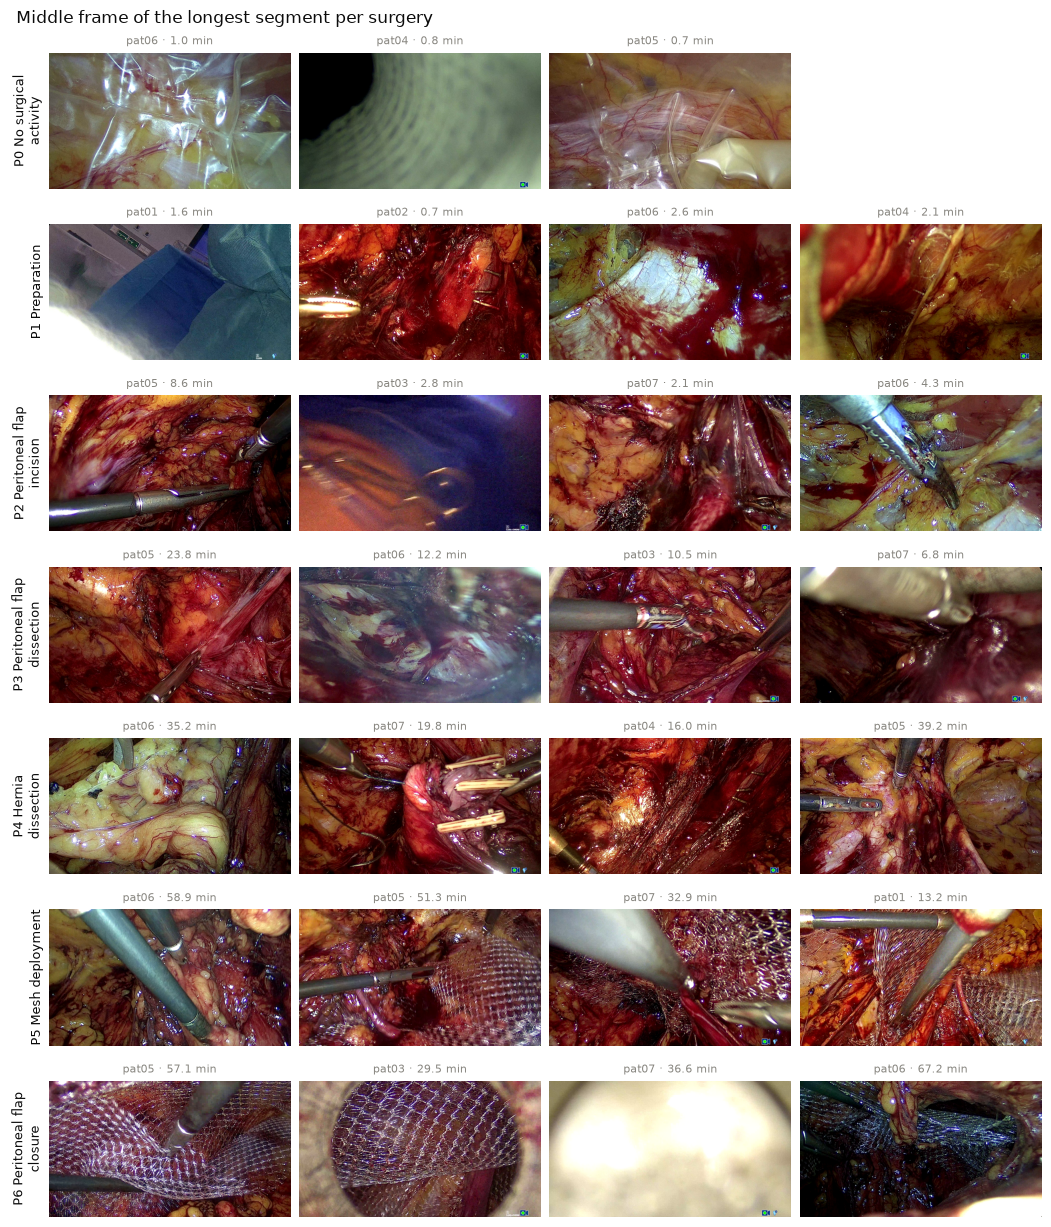

In [25]:
SAMPLES_PER_PHASE = 4

fig, axes = plt.subplots(
    len(phase_ids), SAMPLES_PER_PHASE,
    figsize=(2.6 * SAMPLES_PER_PHASE, 1.75 * len(phase_ids)), layout="constrained", squeeze=False,
)
for row, phase in enumerate(phase_ids):
    picks = (
        segment_table[segment_table["phase"] == phase]
        .sort_values("duration_min", ascending=False)
        .drop_duplicates("surgery")
        .head(SAMPLES_PER_PHASE)
    )
    for column, ax in enumerate(axes[row]):
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if column < len(picks):
            pick = picks.iloc[column]
            index = (pick["start"] + pick["end"]) // 2
            with Image.open(surgeries[pick["surgery"]].frame_paths[index]) as image:
                ax.imshow(image.convert("RGB"))
            ax.set_title(f"{pick['surgery']} · {index / ANALYSIS_FPS / 60:.1f} min", fontsize=8, color=MUTED_INK)
    axes[row, 0].set_ylabel(textwrap.fill(phase_names[row], 18), fontsize=9, color=INK)
fig.suptitle("Middle frame of the longest segment per surgery", x=0.01, ha="left", color=INK)
plt.show()

## Leave-one-surgery-out folds

Phase distribution of each held-out surgery versus its training set.

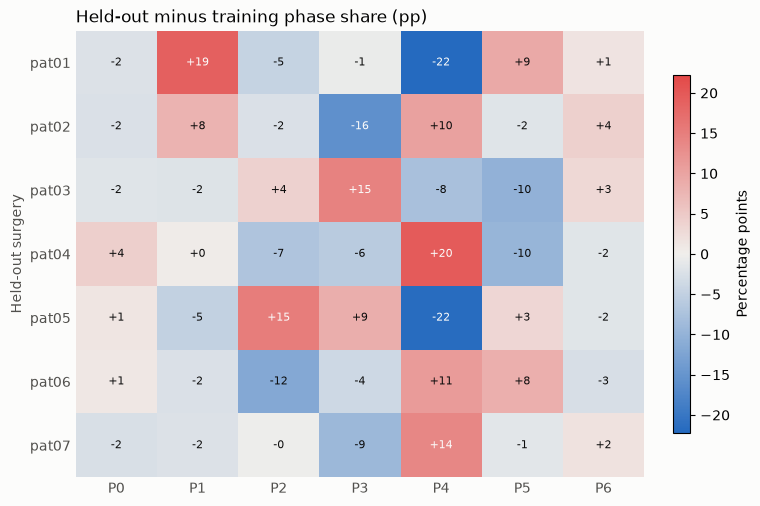

,val,train,total variation,test phases missing in train
test,,,,
pat01,pat02,"pat03, pat04, pat05, pat06, pat07",0.296,
pat02,pat03,"pat01, pat04, pat05, pat06, pat07",0.222,
pat03,pat04,"pat01, pat02, pat05, pat06, pat07",0.216,
pat04,pat05,"pat01, pat02, pat03, pat06, pat07",0.243,
pat05,pat06,"pat01, pat02, pat03, pat04, pat07",0.282,
pat06,pat07,"pat01, pat02, pat03, pat04, pat05",0.204,
pat07,pat01,"pat02, pat03, pat04, pat05, pat06",0.154,


In [26]:
folds = leave_one_surgery_out(list(labels))
rows, gaps = [], {}
for fold in folds:
    train_share = counts.loc[list(fold.train)].sum() / counts.loc[list(fold.train)].to_numpy().sum() * 100
    test_share = share.loc[fold.test]
    gaps[fold.test] = test_share - train_share
    rows.append(
        {
            "test": fold.test,
            "val": fold.val,
            "train": ", ".join(fold.train),
            "total variation": 0.5 * (test_share - train_share).abs().sum() / 100,
            "test phases missing in train": ", ".join(p for p in phase_ids if test_share[p] > 0 and train_share[p] == 0),
        }
    )
gap_table = pd.DataFrame(gaps).T[phase_ids]

fig, ax = plt.subplots(figsize=(7.5, 0.45 * len(gap_table) + 1.8), layout="constrained")
style_axes(ax)
limit = max(gap_table.abs().to_numpy().max(), 1)
image = ax.imshow(gap_table.to_numpy(), cmap=DIVERGING, vmin=-limit, vmax=limit, aspect="auto")
for row in range(len(gap_table)):
    for column in range(len(phase_ids)):
        value = gap_table.iat[row, column]
        ax.text(column, row, f"{value:+.0f}", ha="center", va="center", fontsize=8,
                color=SURFACE if abs(value) > limit * 0.6 else INK)
ax.set_xticks(range(len(phase_ids)), labels=phase_ids)
ax.set_yticks(range(len(gap_table)), labels=gap_table.index)
ax.set_ylabel("Held-out surgery")
ax.set_title("Held-out minus training phase share (pp)", loc="left")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)
fig.colorbar(image, ax=ax, shrink=0.8, label="Percentage points")
plt.show()

pd.DataFrame(rows).set_index("test").round(3)